# Precision, Recall, and Classification Metrics: A Sepsis Screening Perspective

Welcome to this comprehensive tutorial on classification metrics, with a focus on **Precision** and **Recall** in the context of early sepsis detection.

## What You'll Learn
- **Core classification metrics** (Accuracy, Precision, Recall, F1-Score)
- **Why accuracy alone is misleading** in imbalanced scenarios
- **Clinical use cases** (early sepsis screening, deterioration alerts)
- **Confusion matrix** deep dive
- **Trade-offs** between precision and recall
- **ROC and Precision-Recall curves**
- **Real-world decision making** in safety-critical systems
- **Interactive exploration** of threshold effects

> **A note on the data.** Every patient in this notebook is simulated. No real
> or identifiable patient data is used.

---


## 1. Introduction & Setup

First, let's import all necessary libraries.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown

# Suppress warnings
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
warnings.filterwarnings('ignore', category=UserWarning, module='seaborn')

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)

# Set random seed for reproducibility
np.random.seed(42)

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("\n✅ All libraries imported successfully!")

NumPy version: 2.5.3
Pandas version: 3.0.6

✅ All libraries imported successfully!


---
## 2. Understanding the Metrics: Definitions

Let's start with clear definitions in the context of sepsis screening.


### Clinical Use Case: Early Sepsis Detection

Imagine we're building a system that screens every patient on the ward for **sepsis** using routine vital signs and laboratory results.

- **Positive Class**: Patient has sepsis (needs antibiotics within the hour)
- **Negative Class**: Patient does not have sepsis

### The Confusion Matrix

All classification metrics start from the confusion matrix:

```
                    Predicted
                 Negative  Positive
Actual Negative     TN       FP
       Positive     FN       TP
```

Where:
- **TP (True Positive)**: Correctly identified sepsis → ✅ Caught a real case
- **TN (True Negative)**: Correctly cleared a well patient → ✅ No unnecessary workup
- **FP (False Positive)**: Flagged a well patient as septic → ⚠️ False alarm
- **FN (False Negative)**: Missed a real sepsis case → ❌ **DANGEROUS!**

### The Key Metrics

#### 1. **Accuracy**: Overall correctness
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

**In plain English**: Of all predictions, how many were correct?

#### 2. **Precision**: Correctness of positive predictions
$$\text{Precision} = \frac{TP}{TP + FP}$$

**In plain English**: Of all the patients we flagged as septic, how many actually were?

**Clinical Context**: High precision means few false alarms → less wasted clinician time, fewer unnecessary blood cultures, less alarm fatigue

#### 3. **Recall** (Sensitivity): Coverage of actual positives
$$\text{Recall} = \frac{TP}{TP + FN}$$

**In plain English**: Of all the patients who actually have sepsis, how many did we catch?

**Clinical Context**: High recall means we catch most real cases → **critical for survival!** Every hour antibiotics are delayed raises mortality.

#### 4. **F1-Score**: Harmonic mean of precision and recall
$$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

**In plain English**: Balanced measure when you care about both precision and recall


In [2]:
# Demonstrate with a simple example
print("="*60)
print("SIMPLE EXAMPLE: Sepsis Screening")
print("="*60)

# Example predictions from a screening system
# Let's say we screened 100 patients
actual = np.array([0,0,0,0,0,0,0,0,0,0,  # 90 patients without sepsis
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   0,0,0,0,0,0,0,0,0,0,
                   1,1,1,1,1,1,1,1,1,1])  # 10 patients with sepsis

# Model A: Conservative (high recall, lower precision)
predicted_A = np.array([0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        1,1,1,1,1,1,1,1,1,1,  # 10 false alarms
                        1,1,1,1,1,1,1,1,1,1]) # Caught all 10 sepsis cases

# Model B: Aggressive (high precision, lower recall)
predicted_B = np.array([0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        0,0,0,0,0,0,0,0,0,0,
                        1,1,1,1,1,0,0,0,0,0]) # Only caught 5 sepsis cases, but no false alarms

def analyze_model(actual, predicted, model_name):
    cm = confusion_matrix(actual, predicted)
    tn, fp, fn, tp = cm.ravel()
    
    accuracy = accuracy_score(actual, predicted)
    precision = precision_score(actual, predicted)
    recall = recall_score(actual, predicted)
    f1 = f1_score(actual, predicted)
    
    print(f"\n{model_name}:")
    print(f"-" * 40)
    print(f"Confusion Matrix:")
    print(f"  TN={tn:3d}  FP={fp:3d}")
    print(f"  FN={fn:3d}  TP={tp:3d}")
    print(f"\nMetrics:")
    print(f"  Accuracy:  {accuracy:.3f} ({accuracy*100:.1f}% correct overall)")
    print(f"  Precision: {precision:.3f} ({tp}/{tp+fp} flagged patients truly had sepsis)")
    print(f"  Recall:    {recall:.3f} ({tp}/{tp+fn} real sepsis cases were caught)")
    print(f"  F1-Score:  {f1:.3f}")
    
    print(f"\nPractical Meaning:")
    if fp > 0:
        print(f"  ⚠️  {fp} false alarms (unnecessary workups)")
    if fn > 0:
        print(f"  ❌ {fn} missed sepsis cases (SAFETY RISK!)")
    if fn == 0:
        print(f"  ✅ Caught ALL real sepsis cases!")
    if fp == 0:
        print(f"  ✅ No false alarms!")

analyze_model(actual, predicted_A, "Model A: Conservative (Prioritize Safety)")
analyze_model(actual, predicted_B, "Model B: Selective (Minimize False Alarms)")

print("\n" + "="*60)
print("WHICH MODEL SHOULD WE USE?")
print("="*60)
print("\nFor patient safety, Model A is better because:")
print("  • It catches ALL real sepsis cases (100% recall)")
print("  • False alarms are acceptable (just extra workups)")
print("  • Missing sepsis can be fatal")
print("\nModel B misses 50% of sepsis cases - UNACCEPTABLE for safety!")

SIMPLE EXAMPLE: Sepsis Screening

Model A: Conservative (Prioritize Safety):
----------------------------------------
Confusion Matrix:
  TN= 80  FP= 10
  FN=  0  TP= 10

Metrics:
  Accuracy:  0.900 (90.0% correct overall)
  Precision: 0.500 (10/20 flagged patients truly had sepsis)
  Recall:    1.000 (10/10 real sepsis cases were caught)
  F1-Score:  0.667

Practical Meaning:
  ⚠️  10 false alarms (unnecessary workups)
  ✅ Caught ALL real sepsis cases!

Model B: Selective (Minimize False Alarms):
----------------------------------------
Confusion Matrix:
  TN= 90  FP=  0
  FN=  5  TP=  5

Metrics:
  Accuracy:  0.950 (95.0% correct overall)
  Precision: 1.000 (5/5 flagged patients truly had sepsis)
  Recall:    0.500 (5/10 real sepsis cases were caught)
  F1-Score:  0.667

Practical Meaning:
  ❌ 5 missed sepsis cases (SAFETY RISK!)
  ✅ No false alarms!

WHICH MODEL SHOULD WE USE?

For patient safety, Model A is better because:
  • It catches ALL real sepsis cases (100% recall)
  • Fals

---
## 3. Why Accuracy Can Be Misleading

This is crucial in sepsis screening, where the condition is rare on any given ward round!


In [3]:
# Simple visual demonstration of precision-recall tradeoff
# Create a toy example with known probabilities
np.random.seed(42)

# Simulate 50 patients with predicted probabilities
n_samples_demo = 50
n_sepsis_demo = 10  # 10 actually have sepsis

# True labels: 0 = no sepsis, 1 = sepsis
y_true_demo = np.array([0]*40 + [1]*10)

# Simulated probabilities (septic patients tend to have higher probabilities)
proba_no_sepsis = np.random.beta(2, 5, 40)  # Lower probabilities for patients without sepsis
proba_sepsis = np.random.beta(5, 2, 10)  # Higher probabilities for septic patients
y_proba_demo = np.concatenate([proba_no_sepsis, proba_sepsis])

def visualize_threshold_tradeoff(threshold=0.5):
    """Interactive visualization showing precision-recall tradeoff"""
    
    # Apply threshold to get predictions
    y_pred_demo = (y_proba_demo >= threshold).astype(int)
    
    # Calculate confusion matrix
    cm = confusion_matrix(y_true_demo, y_pred_demo)
    tn, fp, fn, tp = cm.ravel()
    
    # Calculate metrics
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # LEFT: Visual representation of classification
    # Sort by probability for better visualization
    sort_idx = np.argsort(y_proba_demo)
    
    colors = []
    for i in sort_idx:
        if y_true_demo[i] == 1 and y_pred_demo[i] == 1:
            colors.append('green')  # TP - correctly caught sepsis
        elif y_true_demo[i] == 1 and y_pred_demo[i] == 0:
            colors.append('red')  # FN - missed sepsis
        elif y_true_demo[i] == 0 and y_pred_demo[i] == 1:
            colors.append('orange')  # FP - false alarm
        else:
            colors.append('lightblue')  # TN - correctly cleared
    
    axes[0].bar(range(n_samples_demo), y_proba_demo[sort_idx], color=colors, edgecolor='black', alpha=0.8)
    axes[0].axhline(threshold, color='blue', linestyle='--', linewidth=3, label=f'Threshold = {threshold:.2f}')
    axes[0].set_xlabel('Patient (sorted by probability)', fontsize=12, weight='bold')
    axes[0].set_ylabel('Predicted Probability of Sepsis', fontsize=12, weight='bold')
    axes[0].set_title('Classification at Different Thresholds', fontsize=14, weight='bold')
    axes[0].legend(loc='upper left', fontsize=11)
    axes[0].set_ylim([0, 1.1])
    axes[0].grid(True, alpha=0.3, axis='y')
    
    # Add legend explaining colors
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='green', edgecolor='black', label=f'TP: Caught sepsis ({tp})'),
        Patch(facecolor='red', edgecolor='black', label=f'FN: Missed sepsis ({fn})'),
        Patch(facecolor='orange', edgecolor='black', label=f'FP: False alarm ({fp})'),
        Patch(facecolor='lightblue', edgecolor='black', label=f'TN: Correctly cleared ({tn})')
    ]
    axes[0].legend(handles=legend_elements, loc='upper left', fontsize=10)
    
    # RIGHT: Metrics display
    axes[1].axis('off')
    
    # Create text summary (removed emojis for matplotlib compatibility)
    summary_text = f"""
THRESHOLD: {threshold:.2f}
{'='*50}

CONFUSION MATRIX:
                 Predicted
               Well   Sepsis
Actual Well    {tn:3d}      {fp:3d}    <- {fp} false alarms
     Sepsis    {fn:3d}      {tp:3d}    <- {fn} missed sepsis cases

METRICS:
  Precision = {tp}/{tp+fp} = {precision:.3f}
  -> Of flagged patients, {precision*100:.1f}% had sepsis
  
  Recall = {tp}/{tp+fn} = {recall:.3f}
  -> Caught {recall*100:.1f}% of all sepsis cases

THE TRADEOFF:
    """
    
    if threshold < 0.4:
        summary_text += f"""
  LOW threshold = HIGH recall ({recall:.1%})
     -> Catches most sepsis cases
     -> But more false alarms ({fp})
     -> Good for SAFETY-CRITICAL systems
        """
    elif threshold > 0.6:
        summary_text += f"""
  HIGH threshold = LOW recall ({recall:.1%})
     -> Fewer false alarms ({fp})
     -> But MISSES sepsis cases ({fn})
     -> DANGEROUS for safety!
        """
    else:
        summary_text += f"""
  BALANCED threshold
     -> Moderate recall ({recall:.1%})
     -> Moderate precision ({precision:.1%})
     -> Trade-off between both
        """
    
    axes[1].text(0.05, 0.95, summary_text, 
                transform=axes[1].transAxes,
                fontsize=11,
                verticalalignment='top',
                fontfamily='monospace',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.show()
    
    # Print summary (emojis work fine in print statements)
    print(f"\n🎯 KEY INSIGHT:")
    if threshold < 0.4:
        print(f"   LOW threshold → Catches {tp}/{tp+fn} sepsis cases but {fp} false alarms")
        print(f"   → GOOD for safety (high recall = {recall:.1%})")
    elif threshold > 0.6:
        print(f"   HIGH threshold → Only {fp} false alarms but MISSES {fn} sepsis cases")
        print(f"   → DANGEROUS for safety (low recall = {recall:.1%})")
    else:
        print(f"   BALANCED threshold → Trade-off between precision and recall")

print("🎛️  INTERACTIVE DEMO: Adjust the threshold slider below")
print("   Watch how precision and recall change!\n")

# Create interactive widget
interact(visualize_threshold_tradeoff,
         threshold=FloatSlider(value=0.5, min=0.1, max=0.9, step=0.05, 
                              description='Decision Threshold',
                              style={'description_width': 'initial'}));

🎛️  INTERACTIVE DEMO: Adjust the threshold slider below
   Watch how precision and recall change!



interactive(children=(FloatSlider(value=0.5, description='Decision Threshold', max=0.9, min=0.1, step=0.05, st…

### 2.5 Visual Demonstration: Precision-Recall Tradeoff

Let's see how adjusting a decision threshold affects precision and recall with a **simple interactive visualization**.

In [4]:
# The "Accuracy Paradox" - a useless but "accurate" model
print("="*60)
print("THE ACCURACY PARADOX")
print("="*60)

# Realistic scenario: only 1% of screened patients actually have sepsis
n_samples = 1000
n_sepsis = 10      # 1% have sepsis
n_no_sepsis = 990  # 99% do not

actual_realistic = np.array([0]*n_no_sepsis + [1]*n_sepsis)

# Naive Model: Just predict "no sepsis" for everyone
predicted_naive = np.zeros(n_samples)

# Smart Model: Actually tries to detect sepsis
# Catches 8 out of 10 cases, but has 30 false alarms
predicted_smart = np.zeros(n_samples)
predicted_smart[960:990] = 1  # 30 false alarms
predicted_smart[990:998] = 1  # Caught 8 real sepsis cases
# predicted_smart[998:1000] = 0  # Missed 2 cases

print("\nScenario: 1000 patients screened")
print("  - 990 do not have sepsis (99%)")
print("  - 10 have sepsis (1%)")

analyze_model(actual_realistic, predicted_naive, "\nNAIVE MODEL: Always predict 'no sepsis'")
analyze_model(actual_realistic, predicted_smart, "\nSMART MODEL: Actually tries to detect sepsis")

print("\n" + "="*60)
print("THE PROBLEM WITH ACCURACY")
print("="*60)
print("\nThe NAIVE model has 99% accuracy but:")
print("  ❌ Misses ALL 10 sepsis cases (0% recall)")
print("  ❌ Completely useless as a safety net")
print("  ❌ Those patients deteriorate untreated")
print("\nThe SMART model has 97% accuracy but:")
print("  ✅ Catches 80% of cases (8/10 recall)")
print("  ✅ Antibiotics start hours earlier for those patients")
print("  ⚠️  Has some false alarms (acceptable cost)")
print("\n🎯 KEY LESSON: In imbalanced datasets, accuracy is misleading!")
print("   Always look at Precision, Recall, and F1-Score.")


THE ACCURACY PARADOX

Scenario: 1000 patients screened
  - 990 do not have sepsis (99%)
  - 10 have sepsis (1%)


NAIVE MODEL: Always predict 'no sepsis':
----------------------------------------
Confusion Matrix:
  TN=990  FP=  0
  FN= 10  TP=  0

Metrics:
  Accuracy:  0.990 (99.0% correct overall)
  Precision: 0.000 (0/0 flagged patients truly had sepsis)
  Recall:    0.000 (0/10 real sepsis cases were caught)
  F1-Score:  0.000

Practical Meaning:
  ❌ 10 missed sepsis cases (SAFETY RISK!)
  ✅ No false alarms!


SMART MODEL: Actually tries to detect sepsis:
----------------------------------------
Confusion Matrix:
  TN=960  FP= 30
  FN=  2  TP=  8

Metrics:
  Accuracy:  0.968 (96.8% correct overall)
  Precision: 0.211 (8/38 flagged patients truly had sepsis)
  Recall:    0.800 (8/10 real sepsis cases were caught)
  F1-Score:  0.333

Practical Meaning:
  ⚠️  30 false alarms (unnecessary workups)
  ❌ 2 missed sepsis cases (SAFETY RISK!)

THE PROBLEM WITH ACCURACY

The NAIVE model has 

/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


---
## 4. Visual Understanding: Confusion Matrix Deep Dive

/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


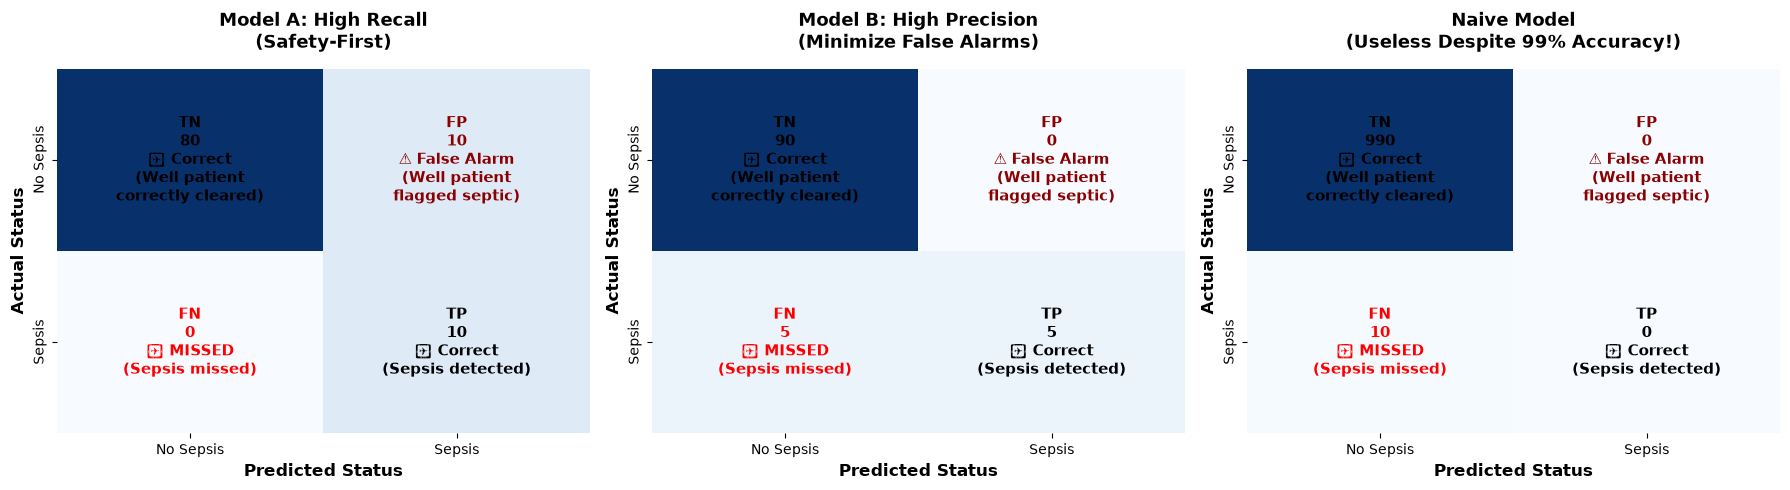

Understanding the Colors and Numbers:

📊 Confusion Matrix Quadrants:
  • Top-Left (TN): True Negatives - correctly identified patients without sepsis
  • Top-Right (FP): False Positives - false alarms (well but flagged)
  • Bottom-Left (FN): False Negatives - MISSED SEPSIS (dangerous!)
  • Bottom-Right (TP): True Positives - correctly detected sepsis cases

🎯 What to Optimize:
  • Maximize TP and TN (correct predictions)
  • Minimize FN (missed sepsis cases are dangerous!)
  • Minimize FP (false alarms waste resources)
  • In safety-critical systems: FN >> FP in importance


In [5]:
# Visualize confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Function to plot confusion matrix with annotations
def plot_confusion_matrix_detailed(cm, ax, title):
    tn, fp, fn, tp = cm.ravel()
    
    # Create the heatmap
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['No Sepsis', 'Sepsis'], yticklabels=['No Sepsis', 'Sepsis'])
    
    # Add custom annotations with meanings
    ax.text(0.5, 0.5, f'TN\n{tn}\n✅ Correct\n(Well patient\ncorrectly cleared)', 
            ha='center', va='center', fontsize=11, weight='bold')
    ax.text(1.5, 0.5, f'FP\n{fp}\n⚠️ False Alarm\n(Well patient\nflagged septic)', 
            ha='center', va='center', fontsize=11, weight='bold', color='darkred')
    ax.text(0.5, 1.5, f'FN\n{fn}\n❌ MISSED\n(Sepsis missed)', 
            ha='center', va='center', fontsize=11, weight='bold', color='red')
    ax.text(1.5, 1.5, f'TP\n{tp}\n✅ Correct\n(Sepsis detected)', 
            ha='center', va='center', fontsize=11, weight='bold')
    
    ax.set_ylabel('Actual Status', fontsize=12, weight='bold')
    ax.set_xlabel('Predicted Status', fontsize=12, weight='bold')
    ax.set_title(title, fontsize=13, weight='bold', pad=15)

# Plot all three scenarios
cm_A = confusion_matrix(actual, predicted_A)
cm_B = confusion_matrix(actual, predicted_B)
cm_naive = confusion_matrix(actual_realistic, predicted_naive)

plot_confusion_matrix_detailed(cm_A, axes[0], 'Model A: High Recall\n(Safety-First)')
plot_confusion_matrix_detailed(cm_B, axes[1], 'Model B: High Precision\n(Minimize False Alarms)')
plot_confusion_matrix_detailed(cm_naive, axes[2], 'Naive Model\n(Useless Despite 99% Accuracy!)')

plt.tight_layout()
plt.show()

print("Understanding the Colors and Numbers:")
print("\n📊 Confusion Matrix Quadrants:")
print("  • Top-Left (TN): True Negatives - correctly identified patients without sepsis")
print("  • Top-Right (FP): False Positives - false alarms (well but flagged)")
print("  • Bottom-Left (FN): False Negatives - MISSED SEPSIS (dangerous!)")
print("  • Bottom-Right (TP): True Positives - correctly detected sepsis cases")

print("\n🎯 What to Optimize:")
print("  • Maximize TP and TN (correct predictions)")
print("  • Minimize FN (missed sepsis cases are dangerous!)")
print("  • Minimize FP (false alarms waste resources)")
print("  • In safety-critical systems: FN >> FP in importance")

---
## 5. Realistic Sepsis Screening Dataset

Let's create a realistic ward-screening dataset of routine vitals and labs.

*All values are simulated from published reference ranges. No real or
identifiable patient data is used.*


In [6]:
# Create a realistic sepsis screening dataset
# Features routinely available at the bedside or from a basic lab panel:
# 1. Serum lactate (higher = tissue hypoperfusion)
# 2. White blood cell count (higher = inflammatory response)
# 3. Body temperature (higher = fever)
# 4. Heart rate (higher = tachycardia)
# 5. Respiratory rate (higher = tachypnoea, an early warning sign)
# 6. Systolic blood pressure (LOWER = hypotension, a late and ominous sign)
# 7. Age (older patients are at higher risk)
# 8. Prior documented infections (0 or 1)

np.random.seed(42)

# Generate imbalanced dataset (5% sepsis rate is realistic for a screened ward)
X, y = make_classification(
    n_samples=2000,
    n_features=8,
    n_informative=6,
    n_redundant=2,
    n_classes=2,
    weights=[0.95, 0.05],  # 5% have sepsis
    flip_y=0.02,  # 2% labeling noise (realistic - chart review disagrees too)
    random_state=42
)

# Name the generated columns. make_classification separates its columns by very
# different amounts, so we hand the strongest columns to the markers that really
# do drive a sepsis screen (lactate, blood pressure, respiratory rate) and the
# weakest to the ones that are genuinely poor discriminators on their own.
generated_names = [
    'Systolic_BP_mmHg',   # strong
    'Temp_DegC',          # weak - afebrile sepsis is common
    'Age_Years',          # weak
    'Prior_Infections',   # weak
    'Resp_Rate_BPM',      # strong
    'Lactate_mmol_L',     # strongest
    'Heart_Rate_BPM',     # moderate
    'WBC_Count',          # weak - the white count can be high, normal or low
]

# The order we want to read them in
feature_names = [
    'Lactate_mmol_L',
    'WBC_Count',
    'Temp_DegC',
    'Heart_Rate_BPM',
    'Resp_Rate_BPM',
    'Systolic_BP_mmHg',
    'Age_Years',
    'Prior_Infections'
]

# Create DataFrame
df_clinical = pd.DataFrame(X, columns=generated_names)[feature_names]
df_clinical['Sepsis'] = y

# make_classification has no idea which way round "sicker" is, so we orient each
# feature to the clinically correct direction of effect before rescaling.
# +1 means the value goes UP in sepsis, -1 means it goes DOWN.
DIRECTION = {
    'Lactate_mmol_L': +1,    # tissue hypoperfusion raises lactate
    'WBC_Count': +1,         # inflammatory response
    'Temp_DegC': +1,         # fever
    'Heart_Rate_BPM': +1,    # tachycardia
    'Resp_Rate_BPM': +1,     # tachypnoea
    'Systolic_BP_mmHg': -1,  # hypotension - blood pressure FALLS
    'Age_Years': +1,         # risk rises with age
    'Prior_Infections': +1,  # prior infection is a risk factor
}
for col, want in DIRECTION.items():
    z = df_clinical[col]
    observed = np.sign(z[y == 1].mean() - z[y == 0].mean())
    if observed != want:
        df_clinical[col] = -z

# Rescale each standardized feature onto a physiologically plausible range,
# then clip so no patient carries an impossible value.
#          column               mean    sd    low    high  decimals
SCALE = [('Lactate_mmol_L',      1.6,   0.8,   0.4,  15.0, 1),
         ('WBC_Count',           9.0,   3.5,   1.0,  40.0, 1),
         ('Temp_DegC',          37.0,   0.7,  34.0,  41.5, 1),
         ('Heart_Rate_BPM',     88.0,  16.0,  40.0, 180.0, 0),
         ('Resp_Rate_BPM',      18.0,   4.0,   6.0,  45.0, 0),
         ('Systolic_BP_mmHg',  122.0,  18.0,  60.0, 210.0, 0),
         ('Age_Years',           58.0, 18.0,  18.0,  98.0, 0)]

for col, mu, sd, lo, hi, dp in SCALE:
    z = df_clinical[col]
    z = (z - z.mean()) / z.std()
    df_clinical[col] = np.clip(mu + sd * z, lo, hi).round(dp)

# Prior infection is a yes/no flag
df_clinical['Prior_Infections'] = (df_clinical['Prior_Infections'] > 0.4).astype(int)

print("🩺 SEPSIS SCREENING DATASET (simulated - no real patient data)")
print("="*60)
print(f"Total patients screened: {len(df_clinical)}")
print(f"Patients with sepsis: {y.sum()} ({y.sum()/len(y)*100:.1f}%)")
print(f"Patients without sepsis: {len(y) - y.sum()} ({(len(y)-y.sum())/len(y)*100:.1f}%)")
print(f"\nFeatures monitored: {len(feature_names)}")
for i, name in enumerate(feature_names, 1):
    print(f"  {i}. {name}")

print("\n📊 Dataset Preview:")
print(df_clinical.head(10))

print("\n📈 Class Distribution:")
print(df_clinical['Sepsis'].value_counts())

print("\n📉 Mean Values by Class:")
print(df_clinical.groupby('Sepsis')[feature_names[:6]].mean().round(1))


🩺 SEPSIS SCREENING DATASET (simulated - no real patient data)
Total patients screened: 2000
Patients with sepsis: 120 (6.0%)
Patients without sepsis: 1880 (94.0%)

Features monitored: 8
  1. Lactate_mmol_L
  2. WBC_Count
  3. Temp_DegC
  4. Heart_Rate_BPM
  5. Resp_Rate_BPM
  6. Systolic_BP_mmHg
  7. Age_Years
  8. Prior_Infections

📊 Dataset Preview:
   Lactate_mmol_L  WBC_Count  Temp_DegC  Heart_Rate_BPM  Resp_Rate_BPM  \
0             2.7        4.5       37.8           100.0           24.0   
1             1.6       10.2       36.7            80.0           18.0   
2             1.0        9.1       36.7            85.0           15.0   
3             0.9        6.6       37.8            81.0           15.0   
4             2.8       11.7       37.7            70.0           14.0   
5             2.0        8.2       37.2            67.0           15.0   
6             2.0        9.5       37.3            81.0           18.0   
7             1.0        3.4       36.0            87.

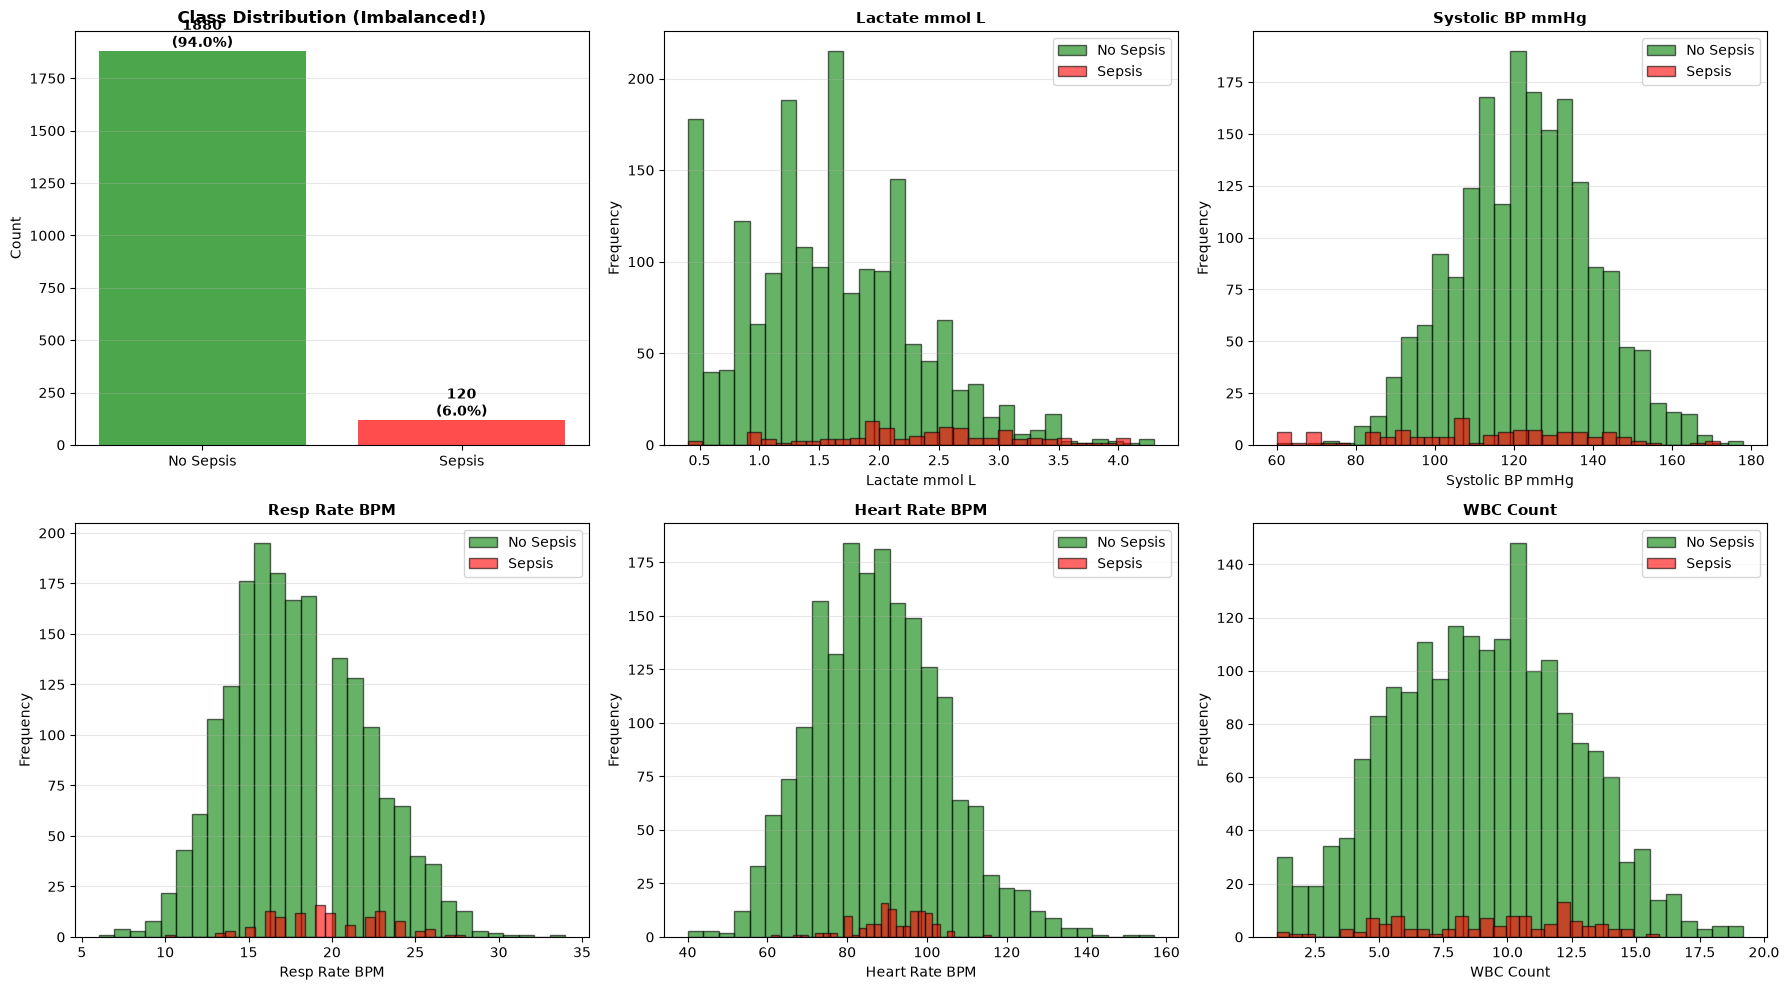

Key Observations:
  • Dataset is highly imbalanced (~5-6% sepsis)
  • The markers that separate the classes clearly:
    - Higher lactate (tissue hypoperfusion)
    - LOWER systolic blood pressure (hypotension)
    - Higher respiratory rate (tachypnoea - the earliest warning sign)
  • The markers that barely separate them at all:
    - Temperature: plenty of septic patients are afebrile
    - White cell count: it can be high, normal, or low in sepsis
  • That is the whole point. No single vital sign is a usable screen,
    which is why we build a model over all of them - and why we have to
    measure it with precision and recall rather than accuracy.


In [7]:
# Visualize the dataset
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

# Class distribution
class_counts = df_clinical['Sepsis'].value_counts()
axes[0].bar(['No Sepsis', 'Sepsis'], class_counts.values, color=['green', 'red'], alpha=0.7)
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Imbalanced!)', fontsize=12, weight='bold')
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 20, f"{v}\n({v/len(df_clinical)*100:.1f}%)", ha='center', fontsize=10, weight='bold')

# Feature distributions by class
key_features = ['Lactate_mmol_L', 'Systolic_BP_mmHg',
                'Resp_Rate_BPM', 'Heart_Rate_BPM', 'WBC_Count']

for idx, feature in enumerate(key_features):
    no_sepsis = df_clinical[df_clinical['Sepsis'] == 0][feature]
    sepsis = df_clinical[df_clinical['Sepsis'] == 1][feature]

    axes[idx+1].hist(no_sepsis, bins=30, alpha=0.6, label='No Sepsis', color='green', edgecolor='black')
    axes[idx+1].hist(sepsis, bins=30, alpha=0.6, label='Sepsis', color='red', edgecolor='black')
    axes[idx+1].set_xlabel(feature.replace('_', ' '))
    axes[idx+1].set_ylabel('Frequency')
    axes[idx+1].set_title(f'{feature.replace("_", " ")}', fontsize=11, weight='bold')
    axes[idx+1].legend()
    axes[idx+1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("Key Observations:")
print("  • Dataset is highly imbalanced (~5-6% sepsis)")
print("  • The markers that separate the classes clearly:")
print("    - Higher lactate (tissue hypoperfusion)")
print("    - LOWER systolic blood pressure (hypotension)")
print("    - Higher respiratory rate (tachypnoea - the earliest warning sign)")
print("  • The markers that barely separate them at all:")
print("    - Temperature: plenty of septic patients are afebrile")
print("    - White cell count: it can be high, normal, or low in sepsis")
print("  • That is the whole point. No single vital sign is a usable screen,")
print("    which is why we build a model over all of them - and why we have to")
print("    measure it with precision and recall rather than accuracy.")


---
## 6. Training Models and Comparing Metrics

In [8]:
# Prepare data
X = df_clinical[feature_names].values
y = df_clinical['Sepsis'].values

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("📦 Data Preparation Complete")
print("="*60)
print(f"Training set: {len(X_train)} samples")
print(f"  - No Sepsis: {(y_train == 0).sum()}")
print(f"  - Sepsis: {(y_train == 1).sum()}")
print(f"\nTest set: {len(X_test)} samples")
print(f"  - No Sepsis: {(y_test == 0).sum()}")
print(f"  - Sepsis: {(y_test == 1).sum()}")

# Train two models with different approaches
print("\n🤖 Training Models...")

# Model 1: Random Forest (default threshold)
rf_default = RandomForestClassifier(n_estimators=100, random_state=42)
rf_default.fit(X_train_scaled, y_train)

# Model 2: Logistic Regression
lr_default = LogisticRegression(random_state=42, max_iter=1000)
lr_default.fit(X_train_scaled, y_train)

print("✅ Models trained!")

# Get predictions
y_pred_rf = rf_default.predict(X_test_scaled)
y_pred_lr = lr_default.predict(X_test_scaled)

# Get prediction probabilities (we'll use these later)
y_proba_rf = rf_default.predict_proba(X_test_scaled)[:, 1]
y_proba_lr = lr_default.predict_proba(X_test_scaled)[:, 1]

# Compare models
def print_model_metrics(y_true, y_pred, y_proba, model_name):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc_score = roc_auc_score(y_true, y_proba)
    
    print(f"\n{model_name}")
    print("="*60)
    print(f"\n📊 Confusion Matrix:")
    print(f"                Predicted")
    print(f"              Well  Sepsis")
    print(f"Actual Well   {tn:4d}   {fp:4d}    ← {fp} false alarms")
    print(f"      Sepsis  {fn:4d}   {tp:4d}    ← {fn} MISSED sepsis cases ❌")
    
    print(f"\n📈 Performance Metrics:")
    print(f"  Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"  Precision: {precision:.4f} ({tp}/{tp+fp} flagged patients truly had sepsis)")
    print(f"  Recall:    {recall:.4f} ({tp}/{tp+fn} real sepsis cases were caught)")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  AUC-ROC:   {auc_score:.4f}")
    
    print(f"\n🎯 Practical Interpretation:")
    print(f"  • Caught {tp} out of {tp+fn} real sepsis cases ({recall*100:.1f}%)")
    print(f"  • Missed {fn} sepsis cases (SAFETY CONCERN!)" if fn > 0 else "  • ✅ No missed sepsis cases!")
    print(f"  • {fp} unnecessary workups (false alarms)")
    print(f"  • Of {tp+fp} flagged patients, {tp} actually had sepsis ({precision*100:.1f}%)")
    
    return {'accuracy': accuracy, 'precision': precision, 'recall': recall, 
            'f1': f1, 'auc': auc_score, 'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp}

metrics_rf = print_model_metrics(y_test, y_pred_rf, y_proba_rf, "Random Forest (Default Threshold)")
metrics_lr = print_model_metrics(y_test, y_pred_lr, y_proba_lr, "Logistic Regression (Default Threshold)")

📦 Data Preparation Complete
Training set: 1500 samples
  - No Sepsis: 1410
  - Sepsis: 90

Test set: 500 samples
  - No Sepsis: 470
  - Sepsis: 30

🤖 Training Models...
✅ Models trained!

Random Forest (Default Threshold)

📊 Confusion Matrix:
                Predicted
              Well  Sepsis
Actual Well    469      1    ← 1 false alarms
      Sepsis    16     14    ← 16 MISSED sepsis cases ❌

📈 Performance Metrics:
  Accuracy:  0.9660 (96.60%)
  Precision: 0.9333 (14/15 flagged patients truly had sepsis)
  Recall:    0.4667 (14/30 real sepsis cases were caught)
  F1-Score:  0.6222
  AUC-ROC:   0.8663

🎯 Practical Interpretation:
  • Caught 14 out of 30 real sepsis cases (46.7%)
  • Missed 16 sepsis cases (SAFETY CONCERN!)
  • 1 unnecessary workups (false alarms)
  • Of 15 flagged patients, 14 actually had sepsis (93.3%)

Logistic Regression (Default Threshold)

📊 Confusion Matrix:
                Predicted
              Well  Sepsis
Actual Well    470      0    ← 0 false alarms
    

🔮 HOW THE MODEL PREDICTS SEPSIS PROBABILITY

📊 Model output for 5 example patients:
----------------------------------------------------------------------

Patient #1:
  Actual Status: No Sepsis
  Model's Probability of Sepsis: 0.0%
  Model's Probability of No Sepsis:   100.0%

  With different thresholds:
    Threshold 0.3: ✅ No workup
    Threshold 0.5: ✅ No workup
    Threshold 0.7: ✅ No workup

Patient #2:
  Actual Status: No Sepsis
  Model's Probability of Sepsis: 14.0%
  Model's Probability of No Sepsis:   86.0%

  With different thresholds:
    Threshold 0.3: ✅ No workup
    Threshold 0.5: ✅ No workup
    Threshold 0.7: ✅ No workup

Patient #3:
  Actual Status: No Sepsis
  Model's Probability of Sepsis: 3.0%
  Model's Probability of No Sepsis:   97.0%

  With different thresholds:
    Threshold 0.3: ✅ No workup
    Threshold 0.5: ✅ No workup
    Threshold 0.7: ✅ No workup

Patient #4:
  Actual Status: No Sepsis
  Model's Probability of Sepsis: 4.0%
  Model's Probability of No Se

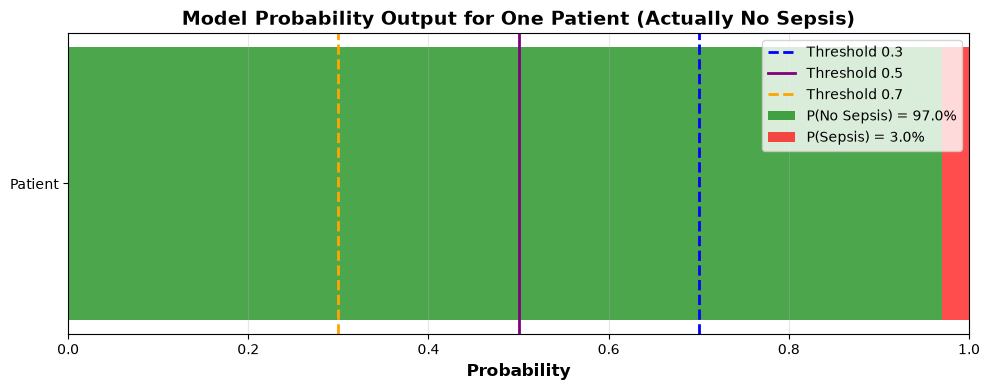


📖 Reading this chart:
   • Green bar: Model's confidence the patient is WELL
   • Red bar: Model's confidence the patient has SEPSIS
   • Vertical lines: Different threshold choices
   • If red portion crosses a threshold line → flag for workup


In [9]:
# =============================================================================
# EXAMPLE: How the Model Predicts Probability of Sepsis
# =============================================================================
# This shows exactly what the model outputs for individual patients

print("🔮 HOW THE MODEL PREDICTS SEPSIS PROBABILITY")
print("=" * 70)

# Pick a few example patients from the test set
example_indices = [0, 5, 10, 15, 20]  # 5 random examples

# Create a DataFrame showing the features and predictions
examples_df = pd.DataFrame(
    X_test_scaled[example_indices], 
    columns=feature_names
)

# Get probabilities from the model
# predict_proba returns [P(No Sepsis), P(Sepsis)] for each sample
proba_no_sepsis = rf_default.predict_proba(X_test_scaled[example_indices])[:, 0]
proba_sepsis = rf_default.predict_proba(X_test_scaled[example_indices])[:, 1]

# Add to our examples
examples_df['True_Label'] = y_test[example_indices]
examples_df['P(No Sepsis)'] = proba_no_sepsis
examples_df['P(Sepsis)'] = proba_sepsis

print("\n📊 Model output for 5 example patients:")
print("-" * 70)

for i, idx in enumerate(example_indices):
    true_label = "SEPSIS" if y_test[idx] == 1 else "No Sepsis"
    p_sepsis = proba_sepsis[i]
    
    print(f"\nPatient #{i+1}:")
    print(f"  Actual Status: {true_label}")
    print(f"  Model's Probability of Sepsis: {p_sepsis:.1%}")
    print(f"  Model's Probability of No Sepsis:   {1-p_sepsis:.1%}")
    
    # Show how threshold affects prediction
    print(f"\n  With different thresholds:")
    for thresh in [0.3, 0.5, 0.7]:
        prediction = "🚨 FLAG FOR SEPSIS WORKUP" if p_sepsis >= thresh else "✅ No workup"
        print(f"    Threshold {thresh}: {prediction}")

print("\n" + "=" * 70)
print("💡 KEY INSIGHT:")
print("   The model outputs a PROBABILITY, not just Yes/No")
print("   YOU choose the threshold to convert probability → prediction")
print("   Lower threshold = catch more sepsis cases (higher recall)")
print("   Higher threshold = fewer false alarms (higher precision)")
print("=" * 70)

# Visualize one patient's probability
fig, ax = plt.subplots(figsize=(10, 4))

# Show probability bar for one example
example_idx = 2
p_sep = proba_sepsis[example_idx]
true_status = "ACTUAL SEPSIS" if y_test[example_indices[example_idx]] == 1 else "Actually No Sepsis"

ax.barh(['Patient'], [1-p_sep], color='green', alpha=0.7, label=f'P(No Sepsis) = {1-p_sep:.1%}')
ax.barh(['Patient'], [p_sep], left=[1-p_sep], color='red', alpha=0.7, label=f'P(Sepsis) = {p_sep:.1%}')

# Add threshold lines
for thresh, color, style in [(0.3, 'blue', '--'), (0.5, 'purple', '-'), (0.7, 'orange', '--')]:
    ax.axvline(1-thresh, color=color, linestyle=style, linewidth=2, label=f'Threshold {thresh}')

ax.set_xlim(0, 1)
ax.set_xlabel('Probability', fontsize=12, weight='bold')
ax.set_title(f'Model Probability Output for One Patient ({true_status})', fontsize=14, weight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print(f"\n📖 Reading this chart:")
print(f"   • Green bar: Model's confidence the patient is WELL")
print(f"   • Red bar: Model's confidence the patient has SEPSIS")
print(f"   • Vertical lines: Different threshold choices")
print(f"   • If red portion crosses a threshold line → flag for workup")

/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


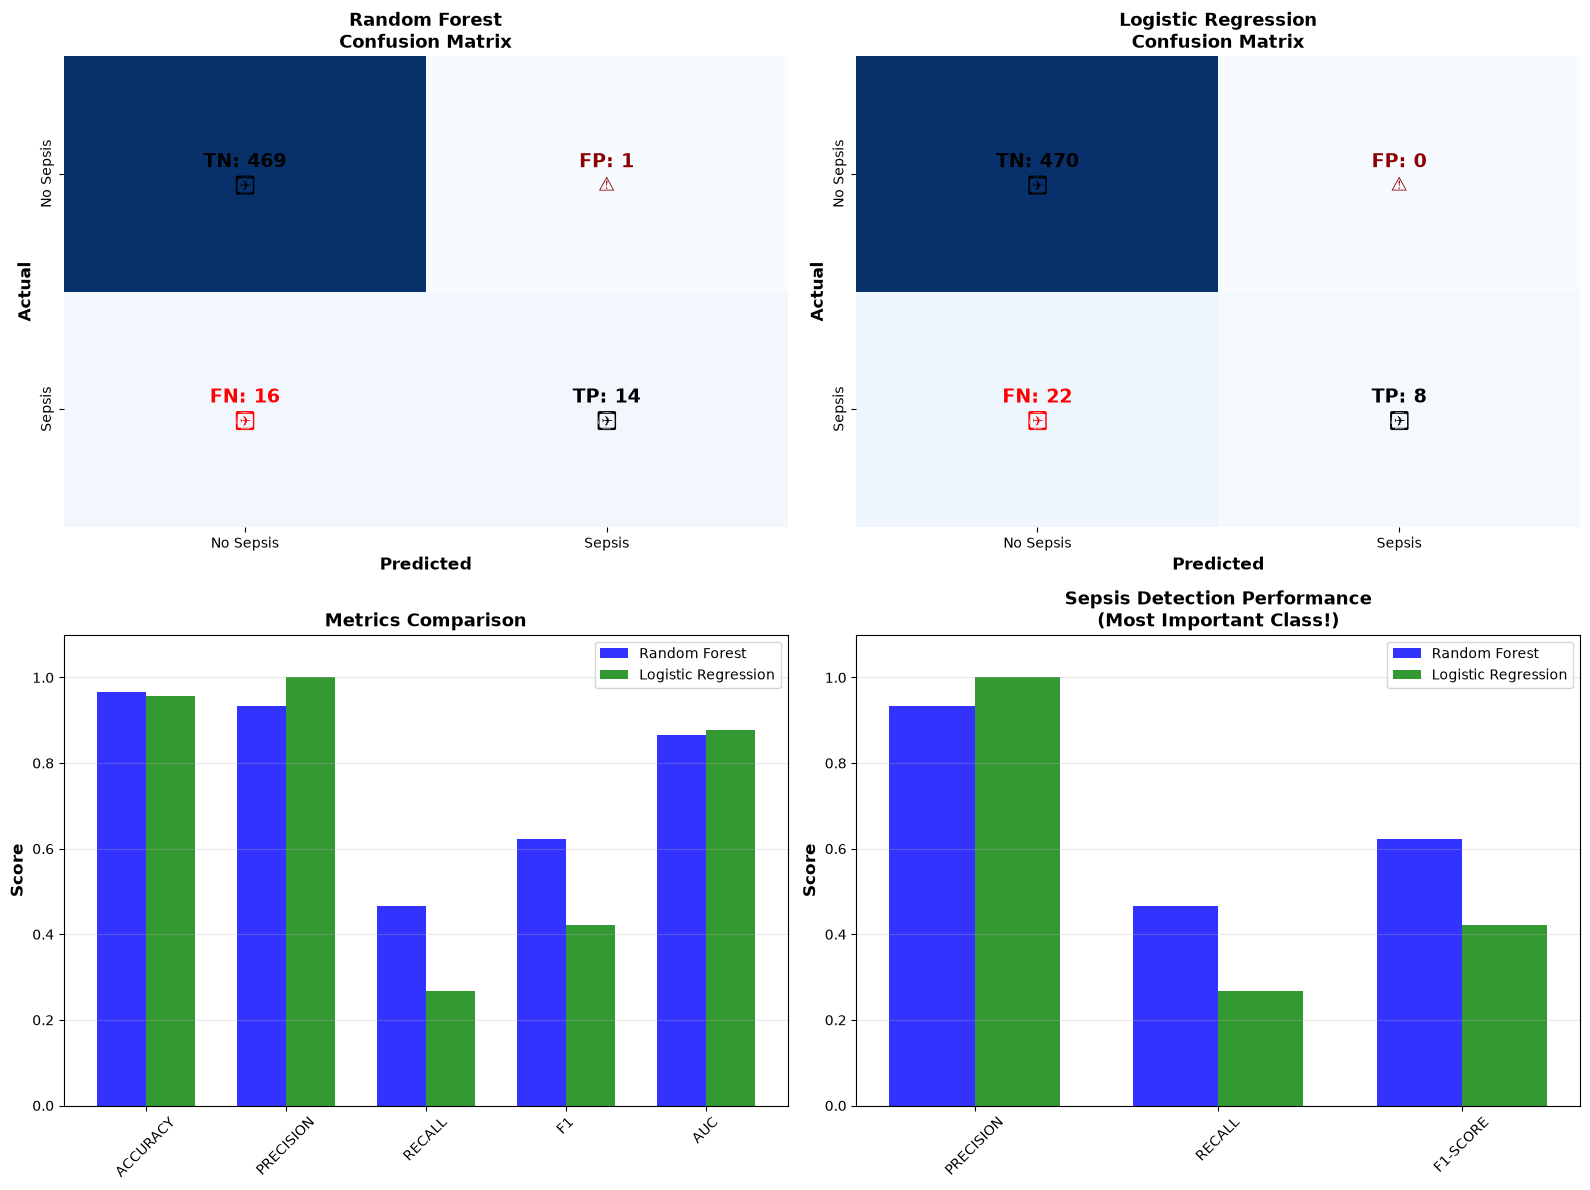


📊 Model Selection Decision:
✅ Random Forest has better RECALL (0.467 vs 0.267)
   → Catches more sepsis cases (better for safety)

In sepsis screening we prioritize RECALL over precision because:
  • Missing a sepsis case can be fatal
  • False alarms just mean extra workups (acceptable cost)


In [10]:
# Visualize model comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Confusion matrices
for idx, (model_name, y_pred) in enumerate([('Random Forest', y_pred_rf), ('Logistic Regression', y_pred_lr)]):
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=axes[0, idx], cbar=False,
                xticklabels=['No Sepsis', 'Sepsis'], yticklabels=['No Sepsis', 'Sepsis'])
    
    # Custom annotations
    axes[0, idx].text(0.5, 0.5, f'TN: {tn}\n✅', ha='center', va='center', 
                     fontsize=14, weight='bold')
    axes[0, idx].text(1.5, 0.5, f'FP: {fp}\n⚠️', ha='center', va='center', 
                     fontsize=14, weight='bold', color='darkred')
    axes[0, idx].text(0.5, 1.5, f'FN: {fn}\n❌', ha='center', va='center', 
                     fontsize=14, weight='bold', color='red')
    axes[0, idx].text(1.5, 1.5, f'TP: {tp}\n✅', ha='center', va='center', 
                     fontsize=14, weight='bold')
    
    axes[0, idx].set_ylabel('Actual', fontsize=12, weight='bold')
    axes[0, idx].set_xlabel('Predicted', fontsize=12, weight='bold')
    axes[0, idx].set_title(f'{model_name}\nConfusion Matrix', fontsize=13, weight='bold')

# Metrics comparison
metrics_comparison = pd.DataFrame([
    {'Model': 'Random Forest', **metrics_rf},
    {'Model': 'Logistic Regression', **metrics_lr}
])

metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1', 'auc']
x_pos = np.arange(len(metrics_to_plot))
width = 0.35

axes[1, 0].bar(x_pos - width/2, metrics_comparison.iloc[0][metrics_to_plot], 
               width, label='Random Forest', alpha=0.8, color='blue')
axes[1, 0].bar(x_pos + width/2, metrics_comparison.iloc[1][metrics_to_plot], 
               width, label='Logistic Regression', alpha=0.8, color='green')
axes[1, 0].set_ylabel('Score', fontsize=12, weight='bold')
axes[1, 0].set_title('Metrics Comparison', fontsize=13, weight='bold')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels([m.upper() for m in metrics_to_plot], rotation=45)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')
axes[1, 0].set_ylim(0, 1.1)

# Classification report visualization
report_rf = classification_report(y_test, y_pred_rf, target_names=['No Sepsis', 'Sepsis'], output_dict=True)
report_lr = classification_report(y_test, y_pred_lr, target_names=['No Sepsis', 'Sepsis'], output_dict=True)

sepsis_metrics = ['precision', 'recall', 'f1-score']
rf_sepsis = [report_rf['Sepsis'][m] for m in sepsis_metrics]
lr_sepsis = [report_lr['Sepsis'][m] for m in sepsis_metrics]

x_pos2 = np.arange(len(sepsis_metrics))
axes[1, 1].bar(x_pos2 - width/2, rf_sepsis, width, label='Random Forest', alpha=0.8, color='blue')
axes[1, 1].bar(x_pos2 + width/2, lr_sepsis, width, label='Logistic Regression', alpha=0.8, color='green')
axes[1, 1].set_ylabel('Score', fontsize=12, weight='bold')
axes[1, 1].set_title('Sepsis Detection Performance\n(Most Important Class!)', fontsize=13, weight='bold')
axes[1, 1].set_xticks(x_pos2)
axes[1, 1].set_xticklabels([m.upper() for m in sepsis_metrics], rotation=45)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')
axes[1, 1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

print("\n📊 Model Selection Decision:")
print("="*60)
if metrics_rf['recall'] > metrics_lr['recall']:
    print(f"✅ Random Forest has better RECALL ({metrics_rf['recall']:.3f} vs {metrics_lr['recall']:.3f})")
    print("   → Catches more sepsis cases (better for safety)")
else:
    print(f"✅ Logistic Regression has better RECALL ({metrics_lr['recall']:.3f} vs {metrics_rf['recall']:.3f})")
    print("   → Catches more sepsis cases (better for safety)")

print(f"\nIn sepsis screening we prioritize RECALL over precision because:")
print(f"  • Missing a sepsis case can be fatal")
print(f"  • False alarms just mean extra workups (acceptable cost)")

---
## 7. The Precision-Recall Trade-off

Understanding how changing the decision threshold affects performance.

In [11]:
# Interactive threshold explorer
def explore_threshold(threshold=0.5, use_model='Random Forest'):
    # Select model
    y_proba = y_proba_rf if use_model == 'Random Forest' else y_proba_lr
    
    # Apply threshold
    y_pred_threshold = (y_proba >= threshold).astype(int)
    
    # Calculate metrics
    cm = confusion_matrix(y_test, y_pred_threshold)
    tn, fp, fn, tp = cm.ravel()
    
    accuracy = accuracy_score(y_test, y_pred_threshold)
    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold, zero_division=0)
    f1 = f1_score(y_test, y_pred_threshold, zero_division=0)
    
    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    
    # 1. Confusion Matrix
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
                xticklabels=['No Sepsis', 'Sepsis'], yticklabels=['No Sepsis', 'Sepsis'])
    
    axes[0].text(0.5, 0.5, f'TN\n{tn}', ha='center', va='center', fontsize=16, weight='bold')
    axes[0].text(1.5, 0.5, f'FP\n{fp}', ha='center', va='center', fontsize=16, weight='bold', color='darkred')
    axes[0].text(0.5, 1.5, f'FN\n{fn}', ha='center', va='center', fontsize=16, weight='bold', color='red')
    axes[0].text(1.5, 1.5, f'TP\n{tp}', ha='center', va='center', fontsize=16, weight='bold')
    
    axes[0].set_ylabel('Actual', fontsize=13, weight='bold')
    axes[0].set_xlabel('Predicted', fontsize=13, weight='bold')
    axes[0].set_title(f'Confusion Matrix\n(Threshold = {threshold:.2f})', fontsize=14, weight='bold')
    
    # 2. Metrics bars
    metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    metrics_values = [accuracy, precision, recall, f1]
    colors = ['lightblue', 'lightgreen', 'lightcoral', 'lightyellow']
    
    bars = axes[1].bar(metrics_names, metrics_values, color=colors, alpha=0.8, edgecolor='black')
    axes[1].set_ylabel('Score', fontsize=13, weight='bold')
    axes[1].set_title('Performance Metrics', fontsize=14, weight='bold')
    axes[1].set_ylim(0, 1.1)
    axes[1].grid(True, alpha=0.3, axis='y')
    
    for i, (bar, value) in enumerate(zip(bars, metrics_values)):
        axes[1].text(bar.get_x() + bar.get_width()/2, value + 0.02, 
                    f'{value:.3f}', ha='center', va='bottom', fontsize=11, weight='bold')
    
    # 3. Probability distribution
    no_sepsis_proba = y_proba[y_test == 0]
    sepsis_proba = y_proba[y_test == 1]
    
    axes[2].hist(no_sepsis_proba, bins=50, alpha=0.6, label='No Sepsis', color='green', edgecolor='black')
    axes[2].hist(sepsis_proba, bins=50, alpha=0.6, label='Sepsis', color='red', edgecolor='black')
    axes[2].axvline(threshold, color='blue', linestyle='--', linewidth=3, label=f'Threshold = {threshold:.2f}')
    axes[2].set_xlabel('Predicted Probability of Sepsis', fontsize=12, weight='bold')
    axes[2].set_ylabel('Frequency', fontsize=12, weight='bold')
    axes[2].set_title('Probability Distributions', fontsize=14, weight='bold')
    axes[2].legend(fontsize=11)
    axes[2].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    # Print interpretation
    print(f"\n{'='*60}")
    print(f"THRESHOLD: {threshold:.2f} | MODEL: {use_model}")
    print(f"{'='*60}")
    print(f"\n📊 Results:")
    print(f"  • Accuracy:  {accuracy:.4f}")
    print(f"  • Precision: {precision:.4f} ({tp}/{tp+fp} flagged patients truly had sepsis)")
    print(f"  • Recall:    {recall:.4f} ({tp}/{tp+fn} real sepsis cases caught)")
    print(f"  • F1-Score:  {f1:.4f}")
    
    print(f"\n🎯 Practical Impact:")
    print(f"  • Caught {tp} out of {tp+fn} sepsis cases")
    print(f"  • Missed {fn} sepsis cases" + (" ❌ UNACCEPTABLE!" if fn > (tp+fn)*0.2 else ""))
    print(f"  • {fp} false alarms (extra workups needed)")
    
    print(f"\n💡 Guidance:")
    if threshold > 0.7:
        print("  ⚠️  High threshold → Fewer alarms but MORE MISSED SEPSIS CASES")
        print("      Not recommended for safety-critical applications!")
    elif threshold < 0.3:
        print("  ✅ Low threshold → Catches more sepsis cases but MORE FALSE ALARMS")
        print("      Good for safety, but increases workup costs")
    else:
        print("  ⚖️  Balanced threshold → Trade-off between precision and recall")

# Create interactive widget
interact(explore_threshold,
         threshold=FloatSlider(value=0.5, min=0.1, max=0.9, step=0.05, description='Threshold'),
         use_model=Dropdown(options=['Random Forest', 'Logistic Regression'], description='Model'));

interactive(children=(FloatSlider(value=0.5, description='Threshold', max=0.9, min=0.1, step=0.05), Dropdown(d…

---
## 8. ROC and Precision-Recall Curves

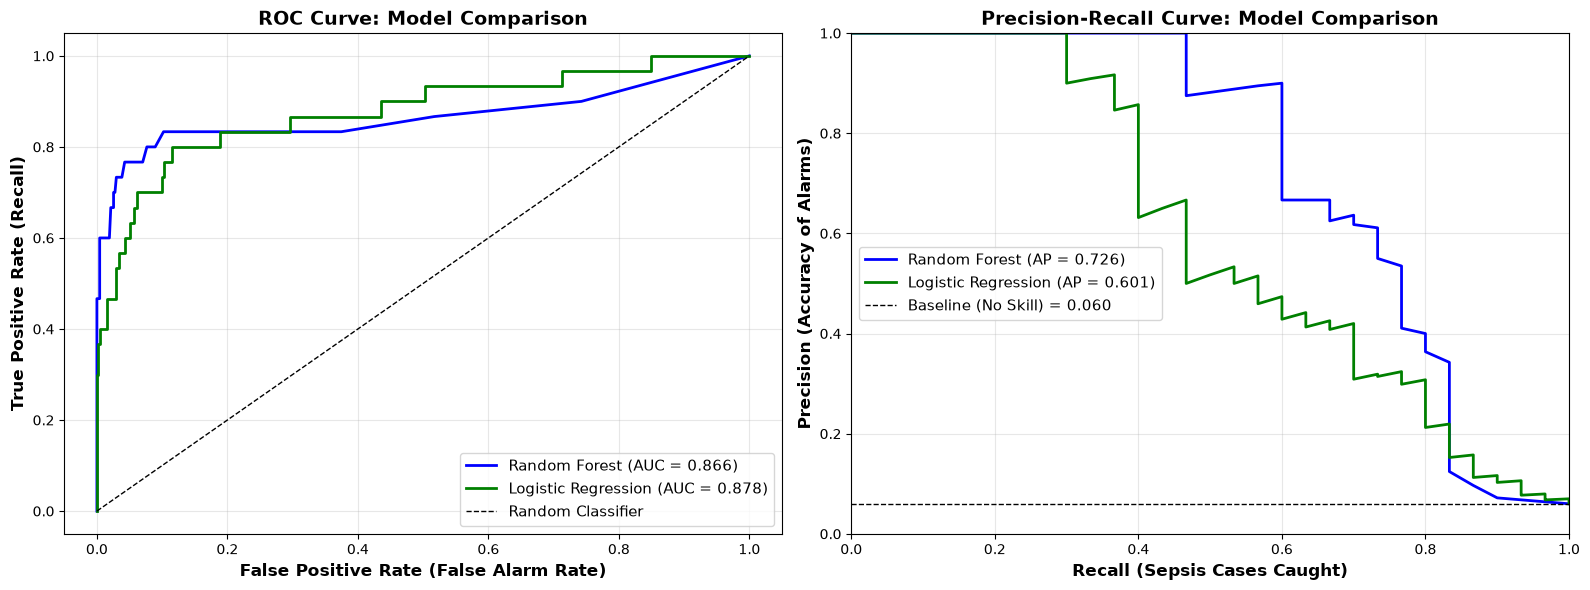

Understanding the Curves:

📈 ROC Curve (Receiver Operating Characteristic):
  • X-axis: False Positive Rate (false alarms)
  • Y-axis: True Positive Rate (recall)
  • Perfect model: Hugs top-left corner (AUC = 1.0)
  • Random model: Diagonal line (AUC = 0.5)
  • Better model: Curve farther from diagonal

📊 Precision-Recall Curve:
  • X-axis: Recall (proportion of sepsis cases caught)
  • Y-axis: Precision (proportion of alarms that are real)
  • Perfect model: Top-right corner (AP = 1.0)
  • Better for imbalanced datasets (like ours!)
  • Shows trade-off: high recall → lower precision

🎯 For Sepsis Screening:
  • We want HIGH RECALL (catch all sepsis cases)
  • We can tolerate LOWER PRECISION (more false alarms OK)
  • Optimal point: Top-right of PR curve (high recall + acceptable precision)

✅ Best model: Random Forest
   (Higher Average Precision = 0.726)


In [12]:
# Generate ROC and PR curves for both models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
auc_rf = roc_auc_score(y_test, y_proba_rf)
auc_lr = roc_auc_score(y_test, y_proba_lr)

axes[0].plot(fpr_rf, tpr_rf, linewidth=2, label=f'Random Forest (AUC = {auc_rf:.3f})', color='blue')
axes[0].plot(fpr_lr, tpr_lr, linewidth=2, label=f'Logistic Regression (AUC = {auc_lr:.3f})', color='green')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[0].set_xlabel('False Positive Rate (False Alarm Rate)', fontsize=12, weight='bold')
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=12, weight='bold')
axes[0].set_title('ROC Curve: Model Comparison', fontsize=14, weight='bold')
axes[0].legend(loc='lower right', fontsize=11)
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curve
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_proba_rf)
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_proba_lr)
ap_rf = average_precision_score(y_test, y_proba_rf)
ap_lr = average_precision_score(y_test, y_proba_lr)

axes[1].plot(recall_rf, precision_rf, linewidth=2, label=f'Random Forest (AP = {ap_rf:.3f})', color='blue')
axes[1].plot(recall_lr, precision_lr, linewidth=2, label=f'Logistic Regression (AP = {ap_lr:.3f})', color='green')

# Add baseline (proportion of positive class)
baseline = y_test.sum() / len(y_test)
axes[1].axhline(y=baseline, color='k', linestyle='--', linewidth=1, label=f'Baseline (No Skill) = {baseline:.3f}')

axes[1].set_xlabel('Recall (Sepsis Cases Caught)', fontsize=12, weight='bold')
axes[1].set_ylabel('Precision (Accuracy of Alarms)', fontsize=12, weight='bold')
axes[1].set_title('Precision-Recall Curve: Model Comparison', fontsize=14, weight='bold')
axes[1].legend(loc='best', fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

print("Understanding the Curves:")
print("="*60)
print("\n📈 ROC Curve (Receiver Operating Characteristic):")
print("  • X-axis: False Positive Rate (false alarms)")
print("  • Y-axis: True Positive Rate (recall)")
print("  • Perfect model: Hugs top-left corner (AUC = 1.0)")
print("  • Random model: Diagonal line (AUC = 0.5)")
print("  • Better model: Curve farther from diagonal")

print("\n📊 Precision-Recall Curve:")
print("  • X-axis: Recall (proportion of sepsis cases caught)")
print("  • Y-axis: Precision (proportion of alarms that are real)")
print("  • Perfect model: Top-right corner (AP = 1.0)")
print("  • Better for imbalanced datasets (like ours!)")
print("  • Shows trade-off: high recall → lower precision")

print("\n🎯 For Sepsis Screening:")
print("  • We want HIGH RECALL (catch all sepsis cases)")
print("  • We can tolerate LOWER PRECISION (more false alarms OK)")
print("  • Optimal point: Top-right of PR curve (high recall + acceptable precision)")
print(f"\n✅ Best model: {'Random Forest' if ap_rf > ap_lr else 'Logistic Regression'}")
print(f"   (Higher Average Precision = {max(ap_rf, ap_lr):.3f})")

---
## 9. Cost-Sensitive Decision Making

In the real world, different types of errors have very different consequences.
A missed sepsis case and an unnecessary blood culture are not remotely the same
kind of mistake.


💰 COST ANALYSIS FOR SEPSIS SCREENING

📋 Cost Structure:
  • Unnecessary workup (FP):  $500   blood cultures, lactate, clinician time
  • Missed sepsis case (FN): $90,000  delayed antibiotics, ICU, mortality risk
  • Correct predictions: $0

  Cost ratio (FN/FP): 180:1
  → Missing a case is 180x more costly (illustrative figures)

📊 Cost Analysis Across Thresholds:
 Threshold  FP  FN  TP  Total_Cost   Recall
       0.1  42   6  24      561000 0.800000
       0.2  16   8  22      728000 0.733333
       0.3  10  10  20      905000 0.666667
       0.4   5  12  18     1082500 0.600000
       0.5   1  16  14     1440500 0.466667
       0.6   0  16  14     1440000 0.466667
       0.7   0  19  11     1710000 0.366667
       0.8   0  25   5     2250000 0.166667
       0.9   0  29   1     2610000 0.033333

🎯 OPTIMAL THRESHOLD: 0.1
   Minimizes total cost: $561,000
   False Positives: 42
   False Negatives: 6
   Recall: 0.800


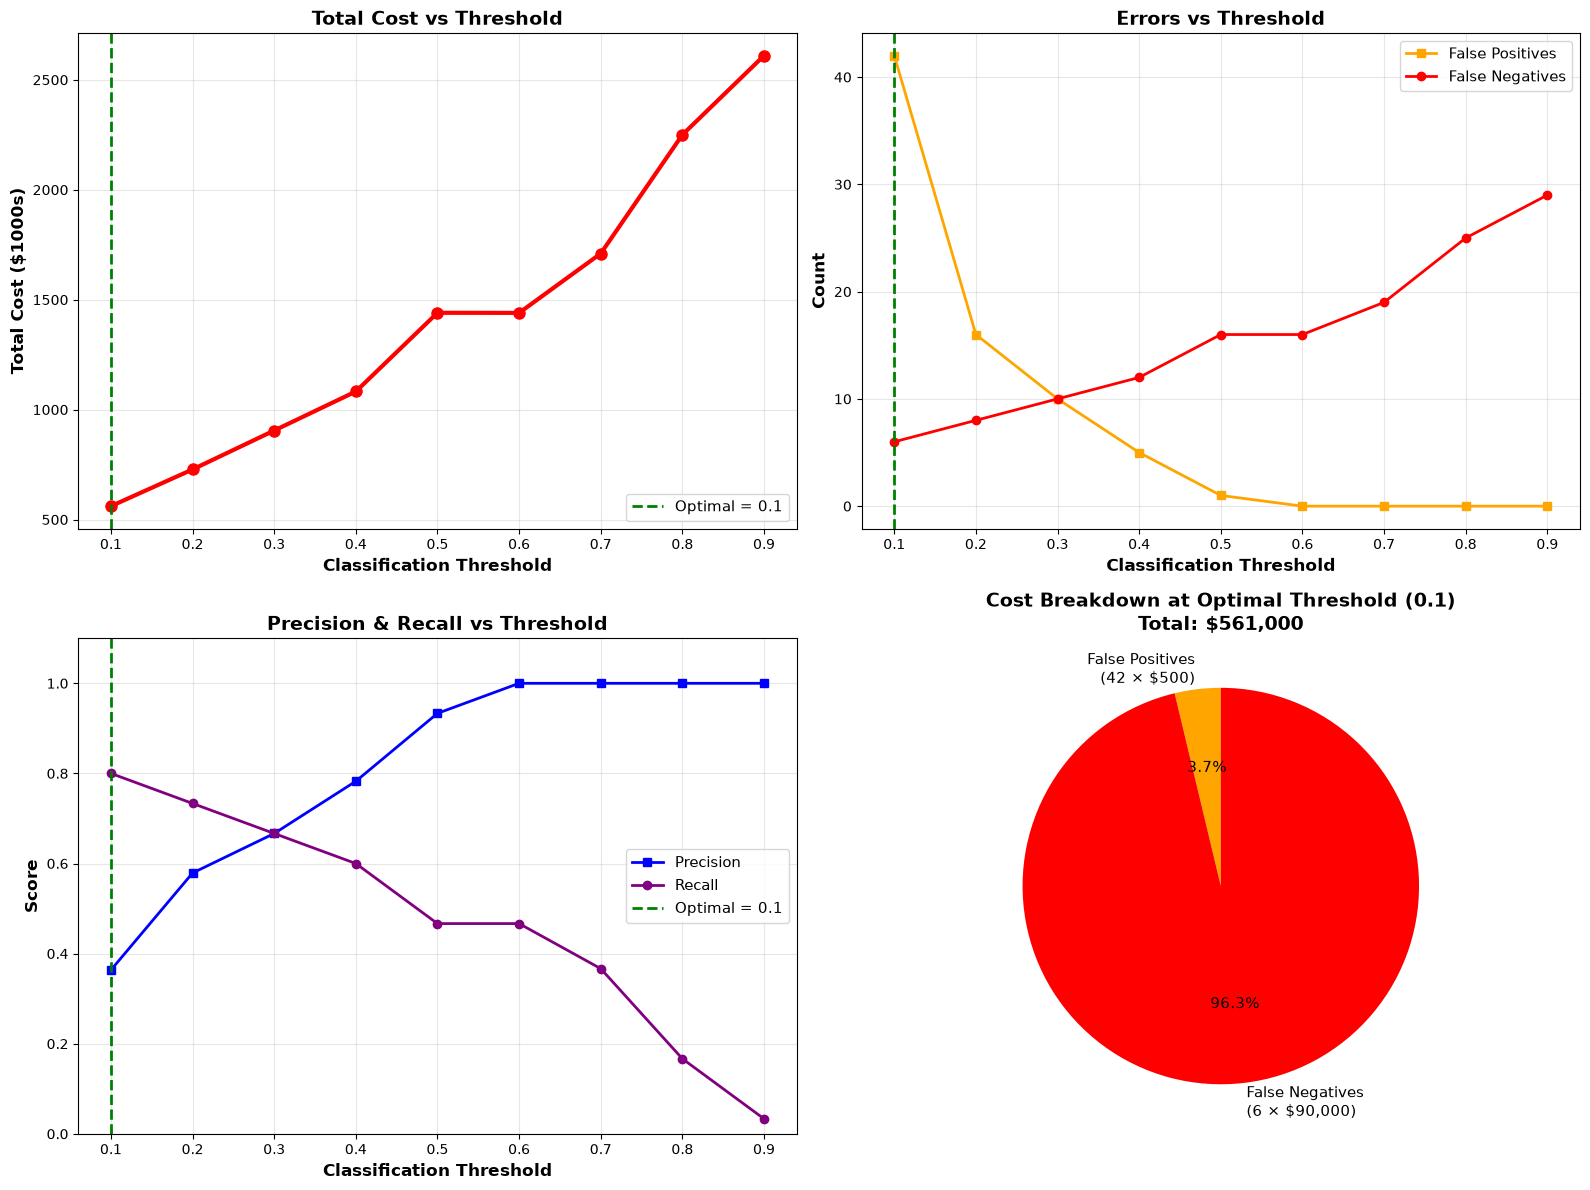


💡 KEY INSIGHTS:
  • Lower threshold → More workups but fewer missed sepsis cases
  • Higher threshold → Fewer workups but MORE MISSED SEPSIS CASES
  • Optimal threshold (0.1) balances costs
  • At optimal: Recall = 80.0% (catching most sepsis cases)

🩺 RECOMMENDATION FOR THE SCREENING PROTOCOL:
  Use threshold = 0.1 to minimize total cost
  This catches 24/30 sepsis cases
  With 42 extra workups


In [13]:
# Cost analysis for the sepsis screening threshold
print("💰 COST ANALYSIS FOR SEPSIS SCREENING")
print("="*60)

# Define realistic costs
cost_workup = 500  # Cost of one unnecessary workup (False Positive)
cost_missed_sepsis = 90000  # Cost of one missed sepsis case (False Negative)
# This could include:
# A missed case typically means:
# - Antibiotics delayed by hours, so a longer and sicker course
# - ICU escalation, vasopressors, organ support
# - Days of extra length of stay
# - A materially raised risk of death
# These figures are ILLUSTRATIVE, not costings from any real institution.

print(f"\n📋 Cost Structure:")
print(f"  • Unnecessary workup (FP):  ${cost_workup:,}   blood cultures, lactate, clinician time")
print(f"  • Missed sepsis case (FN): ${cost_missed_sepsis:,}  delayed antibiotics, ICU, mortality risk")
print(f"  • Correct predictions: $0")
print(f"\n  Cost ratio (FN/FP): {cost_missed_sepsis/cost_workup:.0f}:1")
print(f"  → Missing a case is {cost_missed_sepsis/cost_workup:.0f}x more costly (illustrative figures)")

# Calculate costs for different thresholds
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
results = []

for threshold in thresholds:
    y_pred_thresh = (y_proba_rf >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred_thresh)
    tn, fp, fn, tp = cm.ravel()
    
    # Calculate total cost
    total_cost = (fp * cost_workup) + (fn * cost_missed_sepsis)
    
    # Calculate metrics
    precision = precision_score(y_test, y_pred_thresh, zero_division=0)
    recall = recall_score(y_test, y_pred_thresh, zero_division=0)
    
    results.append({
        'Threshold': threshold,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Total_Cost': total_cost,
        'Precision': precision,
        'Recall': recall
    })

results_df = pd.DataFrame(results)

print(f"\n📊 Cost Analysis Across Thresholds:")
print(results_df[['Threshold', 'FP', 'FN', 'TP', 'Total_Cost', 'Recall']].to_string(index=False))

# Find optimal threshold
optimal_idx = results_df['Total_Cost'].idxmin()
optimal_threshold = results_df.loc[optimal_idx, 'Threshold']
optimal_cost = results_df.loc[optimal_idx, 'Total_Cost']

print(f"\n🎯 OPTIMAL THRESHOLD: {optimal_threshold}")
print(f"   Minimizes total cost: ${optimal_cost:,.0f}")
print(f"   False Positives: {results_df.loc[optimal_idx, 'FP']:.0f}")
print(f"   False Negatives: {results_df.loc[optimal_idx, 'FN']:.0f}")
print(f"   Recall: {results_df.loc[optimal_idx, 'Recall']:.3f}")

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Cost vs Threshold
axes[0, 0].plot(results_df['Threshold'], results_df['Total_Cost'] / 1000, 
                linewidth=3, marker='o', markersize=8, color='red')
axes[0, 0].axvline(optimal_threshold, color='green', linestyle='--', linewidth=2, 
                   label=f'Optimal = {optimal_threshold}')
axes[0, 0].set_xlabel('Classification Threshold', fontsize=12, weight='bold')
axes[0, 0].set_ylabel('Total Cost ($1000s)', fontsize=12, weight='bold')
axes[0, 0].set_title('Total Cost vs Threshold', fontsize=14, weight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# FP and FN vs Threshold
axes[0, 1].plot(results_df['Threshold'], results_df['FP'], linewidth=2, 
                marker='s', label='False Positives', color='orange')
axes[0, 1].plot(results_df['Threshold'], results_df['FN'], linewidth=2, 
                marker='o', label='False Negatives', color='red')
axes[0, 1].axvline(optimal_threshold, color='green', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Classification Threshold', fontsize=12, weight='bold')
axes[0, 1].set_ylabel('Count', fontsize=12, weight='bold')
axes[0, 1].set_title('Errors vs Threshold', fontsize=14, weight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# Precision and Recall vs Threshold
axes[1, 0].plot(results_df['Threshold'], results_df['Precision'], linewidth=2, 
                marker='s', label='Precision', color='blue')
axes[1, 0].plot(results_df['Threshold'], results_df['Recall'], linewidth=2, 
                marker='o', label='Recall', color='purple')
axes[1, 0].axvline(optimal_threshold, color='green', linestyle='--', linewidth=2, 
                   label=f'Optimal = {optimal_threshold}')
axes[1, 0].set_xlabel('Classification Threshold', fontsize=12, weight='bold')
axes[1, 0].set_ylabel('Score', fontsize=12, weight='bold')
axes[1, 0].set_title('Precision & Recall vs Threshold', fontsize=14, weight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim([0, 1.1])

# Cost breakdown at optimal threshold
optimal_fp = results_df.loc[optimal_idx, 'FP']
optimal_fn = results_df.loc[optimal_idx, 'FN']
cost_from_fp = optimal_fp * cost_workup
cost_from_fn = optimal_fn * cost_missed_sepsis

costs = [cost_from_fp / 1000, cost_from_fn / 1000]
labels = [f'False Positives\n({optimal_fp:.0f} × ${cost_workup:,})', 
          f'False Negatives\n({optimal_fn:.0f} × ${cost_missed_sepsis:,})']
colors_pie = ['orange', 'red']

wedges, texts, autotexts = axes[1, 1].pie(costs, labels=labels, autopct='%1.1f%%', 
                                           colors=colors_pie, startangle=90, textprops={'fontsize': 11})
axes[1, 1].set_title(f'Cost Breakdown at Optimal Threshold ({optimal_threshold})\nTotal: ${optimal_cost:,.0f}', 
                     fontsize=14, weight='bold')

plt.tight_layout()
plt.show()

print("\n💡 KEY INSIGHTS:")
print("  • Lower threshold → More workups but fewer missed sepsis cases")
print("  • Higher threshold → Fewer workups but MORE MISSED SEPSIS CASES")
print(f"  • Optimal threshold ({optimal_threshold}) balances costs")
print(f"  • At optimal: Recall = {results_df.loc[optimal_idx, 'Recall']:.1%} (catching most sepsis cases)")
print("\n🩺 RECOMMENDATION FOR THE SCREENING PROTOCOL:")
print(f"  Use threshold = {optimal_threshold} to minimize total cost")
print(f"  This catches {results_df.loc[optimal_idx, 'TP']:.0f}/{results_df.loc[optimal_idx, 'TP'] + results_df.loc[optimal_idx, 'FN']:.0f} sepsis cases")
print(f"  With {optimal_fp:.0f} extra workups")

---
## 10. Summary and Key Takeaways

### 🎯 Key Concepts Recap

#### 1. **The Four Metrics**

```
Accuracy  = (TP + TN) / Total          Overall correctness
Precision = TP / (TP + FP)             Of flagged patients, how many are real?
Recall    = TP / (TP + FN)             Of real sepsis cases, how many did we catch?
F1-Score  = 2 × (P × R) / (P + R)     Harmonic mean of P and R
```

#### 2. **When to Use Each Metric**

| Scenario | Best Metric | Why? |
|----------|-------------|------|
| **Balanced dataset** | Accuracy | Classes are equally important |
| **Imbalanced dataset** | F1-Score, Precision, Recall | Accuracy is misleading |
| **Safety-critical (sepsis screening)** | **RECALL** | Can't afford to miss a case |
| **Spam detection** | Precision | Don't want false positives |
| **Cancer screening** | **RECALL** | Missing a tumour is worse than a false alarm |
| **Fraud detection** | F1-Score | Balance both types of errors |

#### 3. **Clinical Lessons**

For early sepsis detection:
- ✅ **Prioritize RECALL** (catch every case you can)
- ⚠️  Accept lower precision (false alarms mean an extra workup, not a death)
- ❌ **Never use accuracy alone** (misleading when sepsis is rare)
- 💰 Consider **cost-based thresholds** (FN costs >> FP costs)
- 📊 Use **Precision-Recall curves** for imbalanced data

But note the real limit on recall: **alarm fatigue**. A screen that fires on
every third patient gets ignored, and an ignored alert has a recall of zero in
practice. The threshold has to be defensible to the people who answer it.

#### 4. **The Precision-Recall Trade-off**

- **Lower threshold** → More alarms → Higher recall, lower precision
- **Higher threshold** → Fewer alarms → Lower recall, higher precision
- **Can't optimize both simultaneously** (always a trade-off)
- **Choose based on domain requirements** (patient safety vs. workload)

#### 5. **Common Pitfalls to Avoid**

❌ Using accuracy on imbalanced datasets
❌ Ignoring the cost of different error types
❌ Using default threshold (0.5) without analysis
❌ Optimizing precision when you need recall
❌ Not visualizing confusion matrix

✅ Always check class distribution
✅ Calculate all metrics (precision, recall, F1)
✅ Tune threshold based on clinical costs
✅ Use ROC and PR curves for model comparison
✅ Validate on real-world scenarios

### 🩺 Clinical Deployment Best Practices

1. **Set a minimum recall target** (e.g. ≥95% for a sepsis screen)
2. **Cost the errors explicitly** (FN vs FP, in money and in harm)
3. **Optimize the threshold** against that cost, not against accuracy
4. **Retrain regularly** as case mix and care pathways change
5. **Keep a clinician in the loop** - the model triages, it never diagnoses
6. **Monitor performance** over time (data drift, seasonal case mix)

### 📚 Additional Resources

- [Scikit-learn Metrics Guide](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Precision-Recall Explained](https://en.wikipedia.org/wiki/Precision_and_recall)
- [ROC Curves and AUC](https://en.wikipedia.org/wiki/Receiver_operating_characteristic)
- [Imbalanced Learning](https://imbalanced-learn.org/)


In [14]:
print("🎉 PRECISION & RECALL TUTORIAL COMPLETE! 🎉")
print("\n📊 What We Covered:")
print("  ✅ Accuracy, Precision, Recall, and F1-Score definitions")
print("  ✅ Why accuracy is misleading for imbalanced data")
print("  ✅ Confusion matrix deep dive")
print("  ✅ Clinical use case (early sepsis screening)")
print("  ✅ Precision-Recall trade-offs")
print("  ✅ ROC and Precision-Recall curves")
print("  ✅ Cost-sensitive decision making")
print("  ✅ Threshold optimization")
print("  ✅ Interactive exploration tools")
print("\n🎯 Key Takeaway:")
print("   For safety-critical systems like sepsis screening:")
print("   → RECALL is king (a missed case can be fatal)")
print("   → False alarms are acceptable (an extra workup, not a death)")
print("   → Always optimize threshold based on real clinical costs")
print("\n🚀 You're now ready to build effective classification systems!")


🎉 PRECISION & RECALL TUTORIAL COMPLETE! 🎉

📊 What We Covered:
  ✅ Accuracy, Precision, Recall, and F1-Score definitions
  ✅ Why accuracy is misleading for imbalanced data
  ✅ Confusion matrix deep dive
  ✅ Clinical use case (early sepsis screening)
  ✅ Precision-Recall trade-offs
  ✅ ROC and Precision-Recall curves
  ✅ Cost-sensitive decision making
  ✅ Threshold optimization
  ✅ Interactive exploration tools

🎯 Key Takeaway:
   For safety-critical systems like sepsis screening:
   → RECALL is king (a missed case can be fatal)
   → False alarms are acceptable (an extra workup, not a death)
   → Always optimize threshold based on real clinical costs

🚀 You're now ready to build effective classification systems!
